In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

In [3]:
Data=pd.read_csv("sleep_mobile_stress_dataset_15000-selected-columns.csv",index_col=0)
Data.head(1500)

,age,gender,occupation,daily_screen_time_hours,phone_usage_before_sleep_minutes,sleep_duration_hours,sleep_quality_score,stress_level,caffeine_intake_cups,physical_activity_minutes
user_id,,,,,,,,,,
1,56,Female,Designer,3.26,86,5.31,7.72,3.49,0,35
2,46,Female,Teacher,1.85,32,7.36,9.70,3.01,0,16
3,32,Female,Designer,3.04,107,4.50,6.38,5.03,0,17
4,25,Male,Software Engineer,9.00,36,6.68,5.53,10.00,0,3
5,38,Female,Teacher,3.52,56,7.57,6.69,6.71,4,92
...,...,...,...,...,...,...,...,...,...,...
1496,47,Female,Software Engineer,2.38,62,4.57,8.72,1.36,3,105
1497,56,Female,Teacher,6.74,40,5.24,5.16,10.00,1,11
1498,48,Female,Researcher,5.04,74,7.91,7.12,6.33,0,108


In [28]:
Data=Data.replace(to_replace="Other", value="Male")

In [5]:
print(Data.describe())
print(Data.shape)
print(Data.size)

                age  daily_screen_time_hours  \
count  15000.000000             15000.000000   
mean      38.488467                 5.501528   
std       12.007970                 2.600085   
min       18.000000                 1.000000   
25%       28.000000                 3.260000   
50%       38.000000                 5.490000   
75%       49.000000                 7.760000   
max       59.000000                10.000000   

       phone_usage_before_sleep_minutes  sleep_duration_hours  \
count                      15000.000000          15000.000000   
mean                          59.708933              6.509683   
std                           34.641858              1.452689   
min                            0.000000              4.000000   
25%                           29.000000              5.260000   
50%                           60.000000              6.490000   
75%                           90.000000              7.790000   
max                          119.000000        

In [16]:
print("valeurs mnquantes :\n",Data.isna().sum())
print("\nDoublons :",Data.duplicated().sum())
print("\nValeurs uniques :\n",Data.nunique())

valeurs mnquantes :
 age                                 0
gender                              0
occupation                          0
daily_screen_time_hours             0
phone_usage_before_sleep_minutes    0
sleep_duration_hours                0
sleep_quality_score                 0
stress_level                        0
caffeine_intake_cups                0
physical_activity_minutes           0
dtype: int64

Doublons : 0

Valeurs uniques :
 age                                  42
gender                                2
occupation                            8
daily_screen_time_hours             901
phone_usage_before_sleep_minutes    120
sleep_duration_hours                501
sleep_quality_score                 831
stress_level                        900
caffeine_intake_cups                  5
physical_activity_minutes           120
dtype: int64


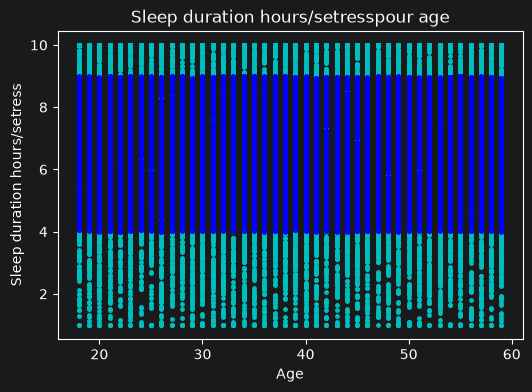

In [17]:
plt.figure(figsize=(6,4))
plt.subplot(111)
plt.plot(Data['age'],Data['stress_level'],marker='o', color="c", linestyle='', markersize=2.5)
plt.plot(Data['age'],Data['sleep_duration_hours'],marker='o', color="b", linestyle='', markersize=2.5)
plt.xlabel("Age")
plt.ylabel("Sleep duration hours/setress")
plt.title("Sleep duration hours/setresspour age")
plt.show()

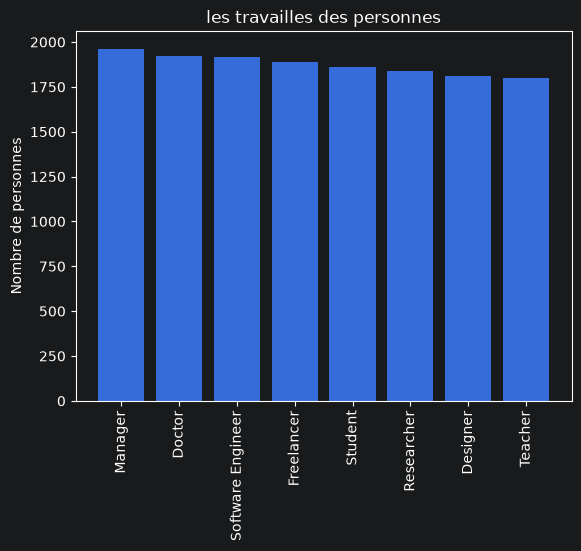

In [18]:
import matplotlib.pyplot as plt
import pandas as pd
plt.figure()
plt.subplot(111)
labels_X=Data['occupation'].value_counts().keys()
valeurs_Y=Data['occupation'].value_counts().values
plt.bar(labels_X, valeurs_Y)
plt.xticks(labels_X,rotation=90)
plt.ylabel("Nombre de personnes")
plt.title("les travailles des personnes")
plt.show()

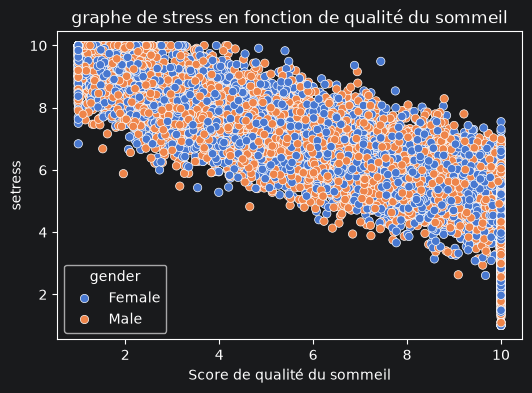

<Figure size 600x400 with 0 Axes>

<Figure size 600x600 with 0 Axes>

In [19]:
plt.figure(figsize=(6,4))
plt.subplot(111)
sns.scatterplot(data=Data,x='stress_level',y='sleep_quality_score',hue='gender',palette='muted')
plt.xlabel("Score de qualité du sommeil")
plt.ylabel("setress")
plt.title("graphe de stress en fonction de qualité du sommeil")
plt.show()
plt.figure(figsize=(6,4))
plt.show()
plt.figure(figsize=(6,6))
plt.show()

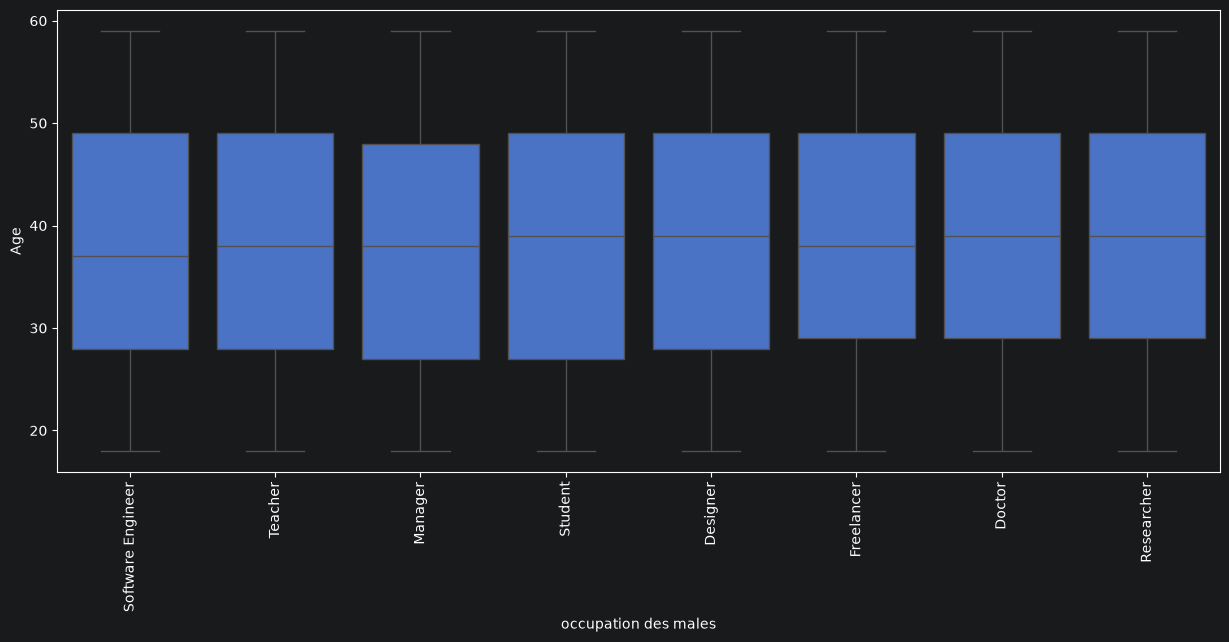

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=[15,6])
plt.subplot(111)
data1=Data.loc[Data['gender']=='Male']
sns.boxplot(x='occupation', y='age', data=data1)
plt.xticks(rotation=90)
plt.xlabel("occupation des males")
plt.ylabel("Age")
plt.show()
plt.show()

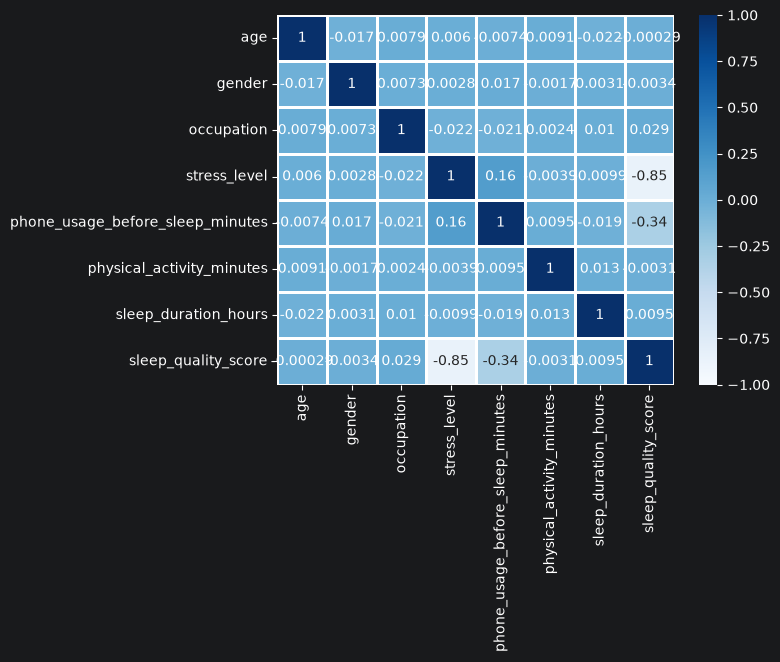

In [36]:
data_heatmap=Data[(Data['occupation']=='Software Engineer')|(Data['occupation']=='Manager')|(Data['occupation']=='Designer')]
data_heatmap=data_heatmap[['age','gender','occupation','stress_level','phone_usage_before_sleep_minutes','physical_activity_minutes','sleep_duration_hours','sleep_quality_score']]
data_heatmap['gender']=data_heatmap['gender'].map({'Male':1,'Female':0})
data_heatmap['occupation']=data_heatmap['occupation'].map({'Software Engineer':1,'Manager':2,'Designer':3})
correlation = data_heatmap.corr()
sns.heatmap(correlation, annot=True, linewidths=1.0, cmap="Blues", vmin=-1, vmax=1)
plt.show()

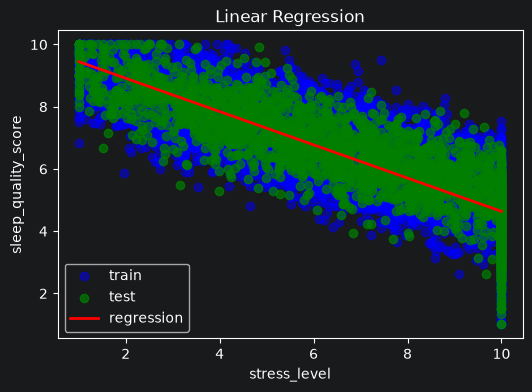

R² train : 0.735413510350139
R² test  : 0.7344415197478386
Coefficient : -0.5347969512127958
Intercept   : 9.98425219178596


In [38]:
X = Data[["stress_level"]]
y = Data["sleep_quality_score"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
X_line = X_test.sort_values(by="stress_level")
y_line = model.predict(X_line)
plt.figure(figsize=(6, 4))
plt.scatter(X_train, y_train, color="blue", alpha=0.5, label="train")
plt.scatter(X_test, y_test, color="green", alpha=0.7, label="test")
plt.plot(X_line, y_line, color="red", linewidth=2, label="regression")
plt.xlabel("stress_level")
plt.ylabel("sleep_quality_score")
plt.title("Linear Regression")
plt.legend()
plt.show()
print("R² train :", model.score(X_train, y_train))
print("R² test  :", r2_score(y_test, y_pred))
print("Coefficient :", model.coef_[0])
print("Intercept   :", model.intercept_)